# D12. Whisper Full Fine-tuning: Seq2SeqTrainer · Data Collator · 학습 모니터링

**음성 AI 전문가 과정 (160h) | 3주차 M3 한국어 ASR Fine-tuning | 4시간**

## 학습 목표
1. **Fine-tuning**이 무엇이고 Full · Encoder 고정 · LoRA(D13)가 어떻게 다른지 말할 수 있다.
2. **Teacher forcing**과 **Cross-Entropy loss**로 Whisper가 '정답 다음 글자 맞히기'를 배우는 원리를 설명한다.
3. 길이가 다른 샘플을 묶는 **Data Collator**를 만들고, 패딩을 **−100**으로 바꾸는 이유를 안다.
4. 생성 결과로 **CER을 재는 `compute_metrics`** 를 만들고 학습 전 성능(baseline)을 잰다.
5. **`Seq2SeqTrainingArguments` · `Seq2SeqTrainer`** 로 Whisper small을 한국어 데이터에 Full Fine-tuning 한다.
6. **TensorBoard**(· 선택 W&B)로 loss · CER 곡선을 보고 **과적합 · 학습률 문제**를 읽어 낸다.
7. 학습 **전 · 후 받아쓰기를 비교**하고, 모델을 저장해 `pipeline`으로 다시 불러 쓴다.

## 오늘의 실습 흐름
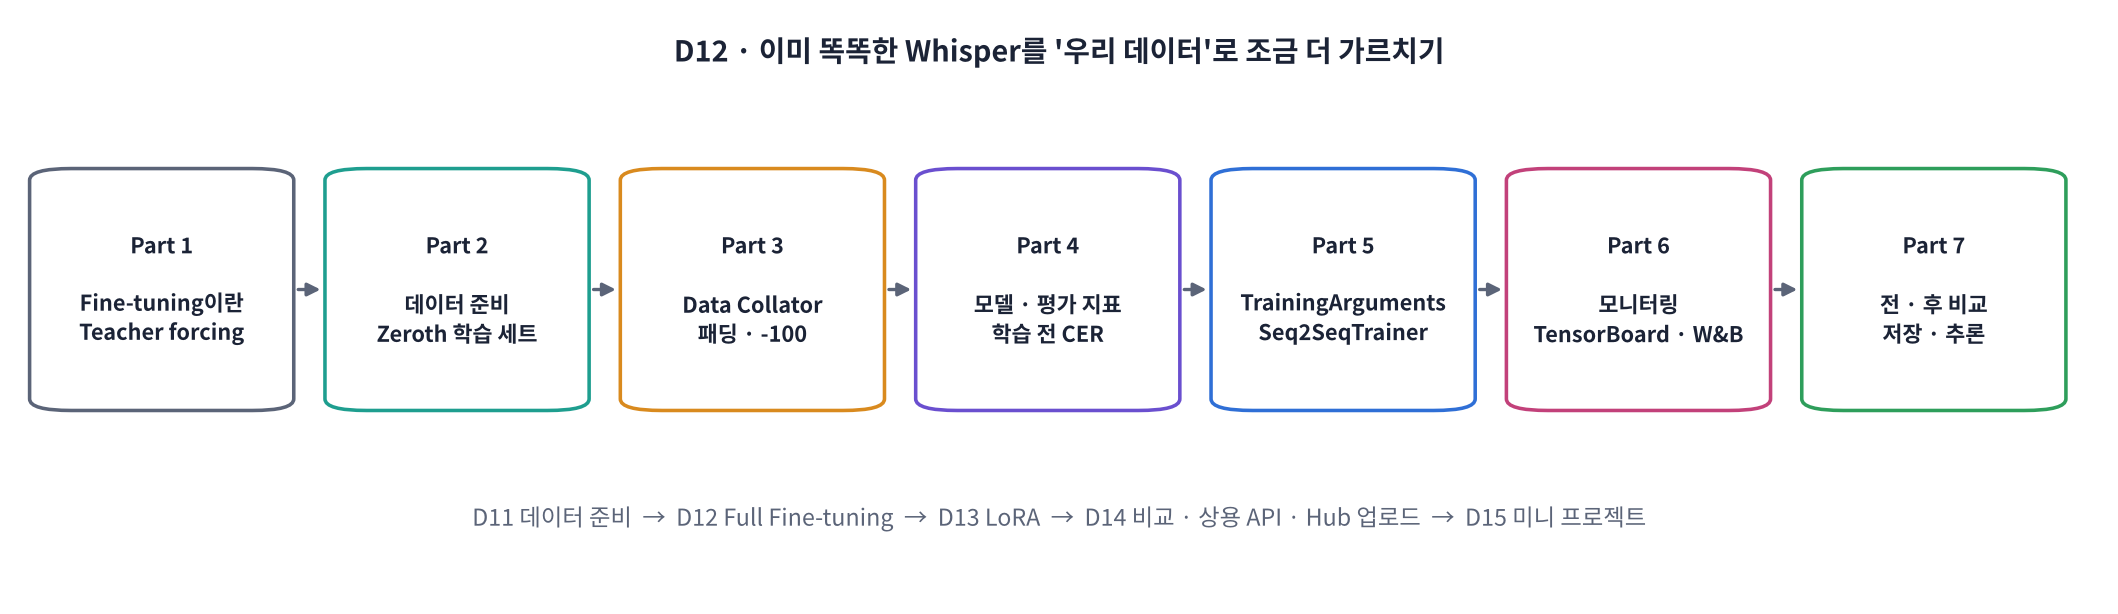

| 교시 | 내용 | 실습 |
|---|---|---|
| 1교시 | Fine-tuning 개념, Teacher forcing, 데이터 준비 (Zeroth 학습 세트) | Part 0 ~ 2, 워크시트 1교시 |
| 2교시 | Data Collator, 평가 지표(CER), 학습 전 성능 재기 | Part 3 ~ 4, 워크시트 2교시 |
| 3교시 | 학습 설정 · Trainer · **학습 실행 (약 20~30분)**, 그동안 메모리 · 학습률 이야기 | Part 5, 워크시트 3교시 |
| 4교시 | TensorBoard 곡선 읽기, 전 · 후 비교, 저장 · 추론 | Part 6 ~ 8, 워크시트 4교시 · 노션 제출 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day12/animation.html) | 각 Part 설명을 볼 때 (Part마다 바로가기 링크가 있습니다) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day12/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다. `!`로 시작하는 줄은 리눅스 명령, `%`로 시작하는 줄은 노트북 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🔍 **코드 해설** | 주요 코드를 한 줄씩 |

> ⚙️ **[런타임] → [런타임 유형 변경] → T4 GPU** 를 먼저 고르세요. GPU가 없으면 노트북이 자동으로 **맛보기 모드**(whisper-tiny · 아주 짧은 학습)로 바뀝니다. 동작 확인은 되지만 성능 향상은 기대하기 어렵습니다.
>
> ⏱️ 3교시 학습 셀은 T4에서 **약 20~30분** 걸립니다. 학습이 도는 동안 슬라이드 · 애니메이션으로 메모리와 학습률 이야기를 합니다.

> 🎬 **애니메이션 D12-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day12/animation.html#flow) — Part 1~7 로드맵

## Part 0. 준비

> 🛠️ **버전 충돌 방지 (D8 · D11과 같은 방식)**: Colab에 미리 깔린 `torch` · `transformers` · `accelerate` · `datasets` · `huggingface_hub` 등의 버전을 **그대로 고정**(constraints)한 채 필요한 것만 설치합니다. 런타임을 다시 시작할 필요가 없습니다. `Seq2SeqTrainer`는 `accelerate`가 있어야 동작합니다.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "transformers", "tokenizers", "huggingface-hub",
        "datasets", "accelerate", "click", "numpy", "protobuf"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))

!pip install -q -c colab_constraints.txt datasets accelerate jiwer tensorboard soundfile librosa
print("✅ 설치 완료")

In [ ]:
import os, io, re, time, random
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
import jiwer
import matplotlib.pyplot as plt
from IPython.display import Audio, display

SR = 16000
random.seed(0); np.random.seed(0); torch.manual_seed(0)

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

import importlib.metadata as md
print(" · ".join(f"{p} {md.version(p)}" for p in ["torch", "transformers", "accelerate", "datasets", "jiwer"]))
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} · 메모리 {p.total_memory / 1024**3:.1f} GB")
else:
    print("⚠️ GPU 없음 → 맛보기 모드로 진행합니다 ([런타임] → [런타임 유형 변경] → T4 GPU 권장)")

### 0-1. 오늘의 실험 설정
한 곳에 모아 두면 나중에 바꿔 실험하기 쉽습니다. GPU가 없으면 자동으로 작게 줄입니다.

In [ ]:
GPU = torch.cuda.is_available()
CFG = dict(
    model_name = "openai/whisper-small" if GPU else "openai/whisper-tiny",   # 2.4억 / 3,900만 파라미터
    n_train    = 2000 if GPU else 64,      # Zeroth 학습 세트에서 가져올 발화 수 (2,000개 ≈ 4.6시간)
    n_test     = 100  if GPU else 16,      # 공식 시험 세트에서 고를 발화 수
    max_steps  = 300  if GPU else 20,      # 학습 step 수 (step 하나 = 묶음 하나로 한 번 고치기)
    batch      = 8,                        # GPU 한 번에 넣는 샘플 수
    accum      = 2,                        # 기울기 모으기 → 실제 묶음 크기 = 8 × 2 = 16
    eval_steps = 100  if GPU else 10,      # 몇 step마다 평가할지
    out_dir    = "whisper-small-ko" if GPU else "whisper-tiny-ko",
)
for k, v in CFG.items():
    print(f"{k:11s} = {v}")

## Part 1. Fine-tuning이란: '이미 똑똑한 모델에게 과외하기'

> 💬 **쉽게 말하면**: Whisper는 68만 시간의 소리로 **이미 공부를 마친 모델**(Pre-trained)입니다. Fine-tuning은 이 모델을 **우리 분야 데이터 몇 시간**으로 조금 더 가르쳐, 우리 말투 · 용어 · 녹음 환경에 맞게 **가중치를 살짝 고치는 일**입니다. 오늘은 모든 가중치를 고치는 **Full Fine-tuning**을 합니다.

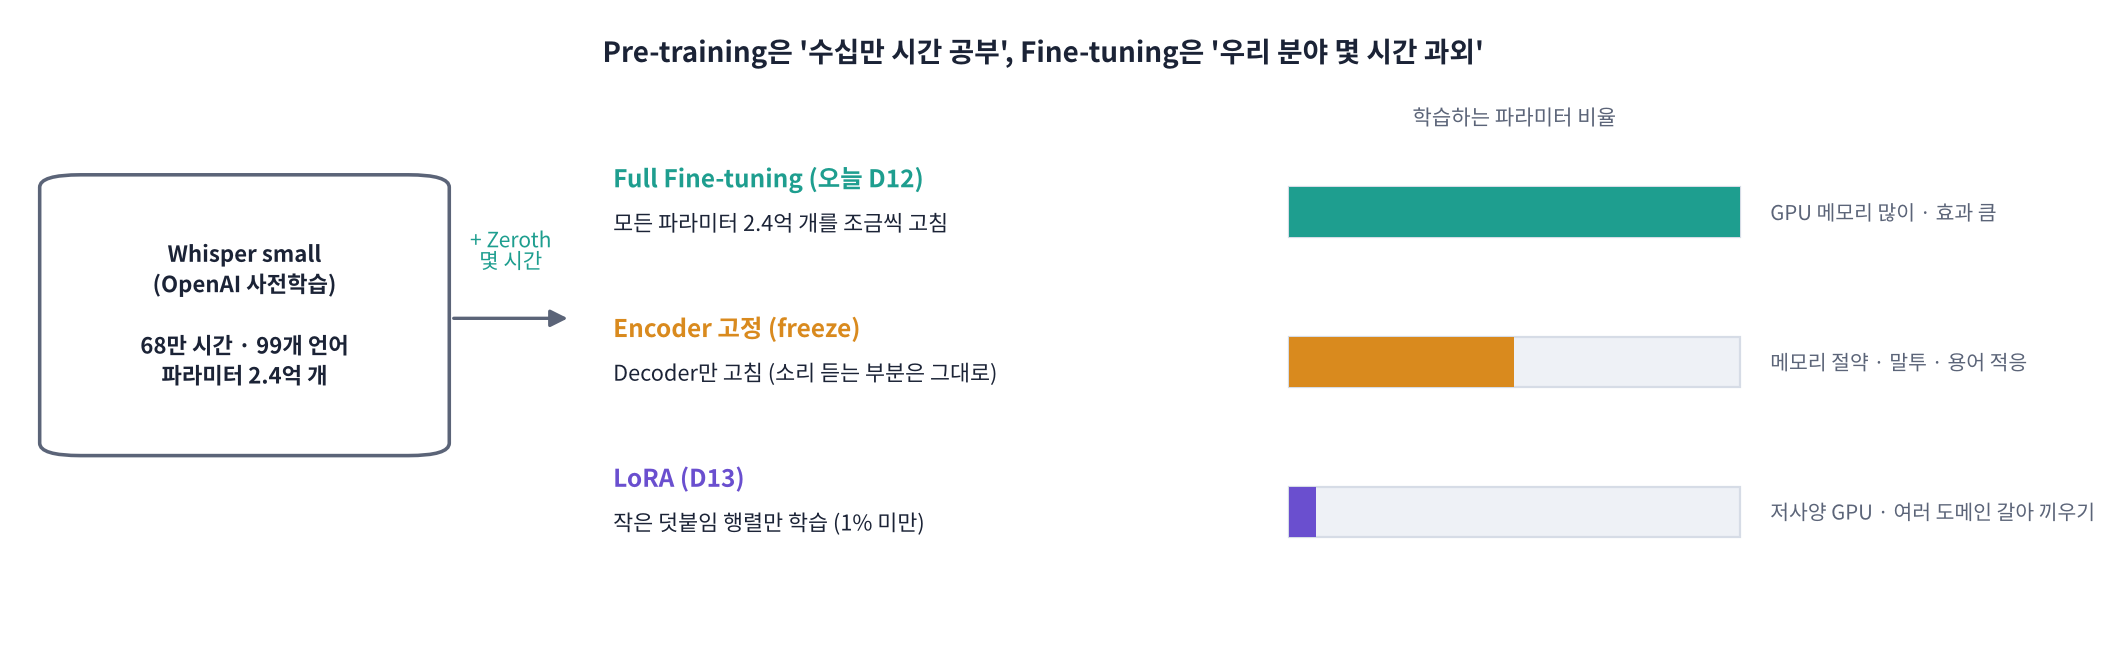

> 🍎 **비유: 경력직 신입사원 교육.** 이미 일을 잘하는 경력직(Whisper)에게 회사 용어 · 업무 방식(우리 데이터)을 며칠 가르칩니다. 처음부터 가르치는 것(처음부터 학습)보다 훨씬 빠르지만, 너무 세게 가르치면 원래 알던 것을 잊어버립니다(**catastrophic forgetting**). 그래서 **학습률을 아주 작게** 씁니다.

> 🎬 **애니메이션 D12-2:** [Fine-tuning 방식 비교](https://imguru-mooc.github.io/AI_Voice/day12/animation.html#finetune) — Full · Encoder 고정 · LoRA가 고치는 파라미터와 메모리

### 1-1. Teacher forcing: Decoder는 '정답 앞부분'을 보며 다음 글자를 맞힌다

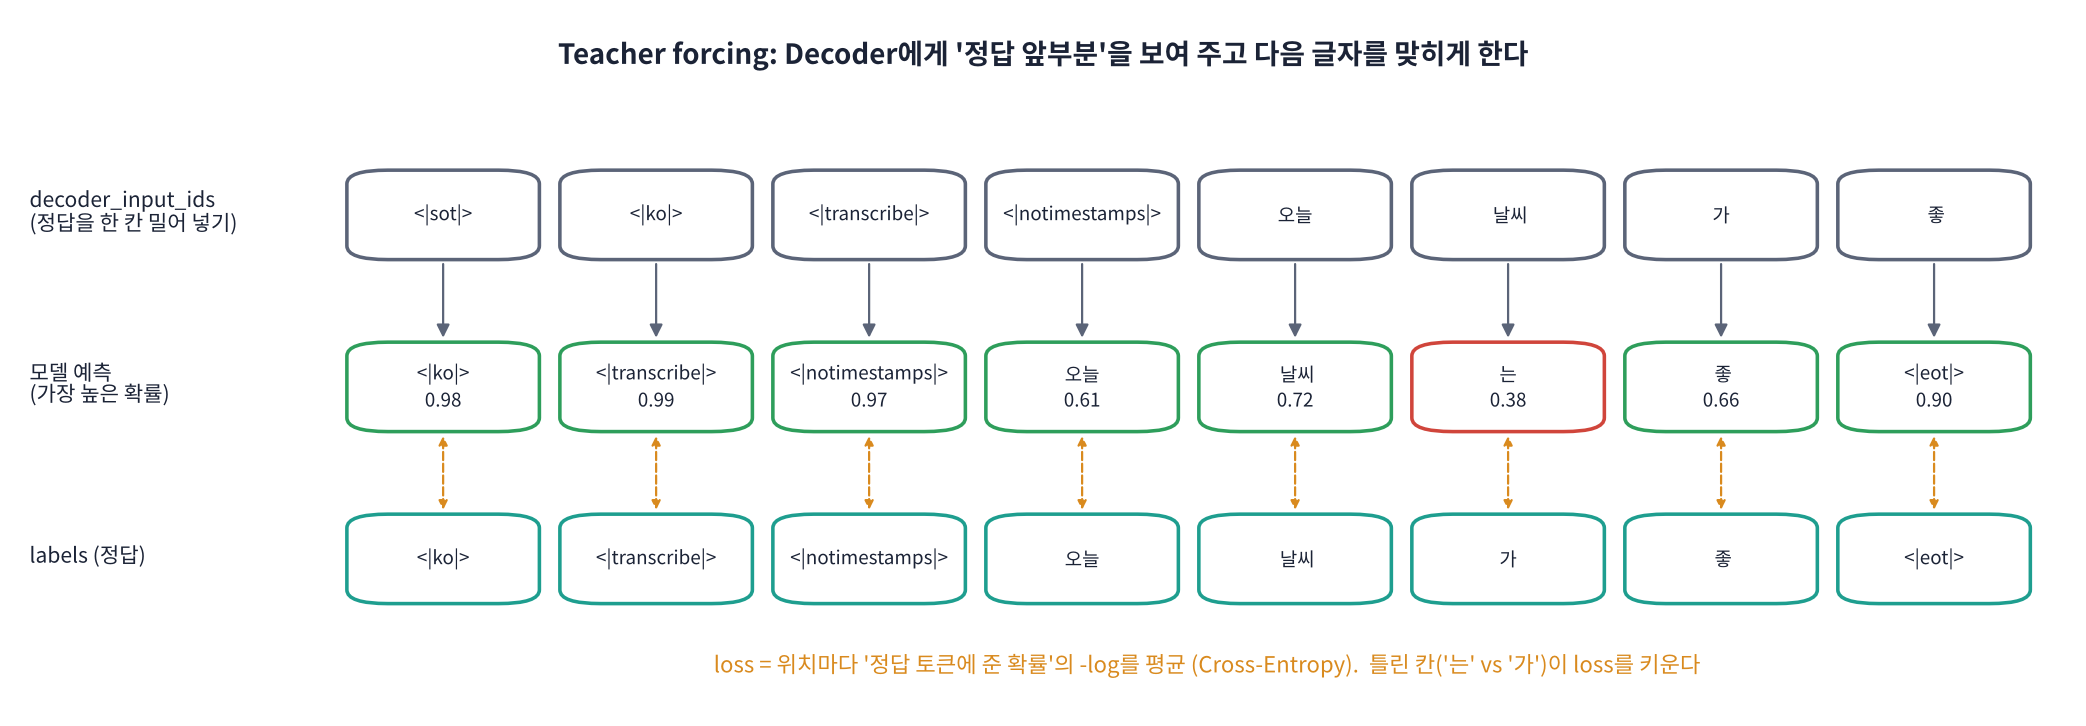

👣 **한 단계씩**
1. 전사를 토큰으로 바꿉니다: `<|startoftranscript|> <|ko|> <|transcribe|> <|notimestamps|> 오늘 날씨 …`
2. Decoder 입력(`decoder_input_ids`)은 **정답을 한 칸 오른쪽으로 민 것**, 맞힐 정답(`labels`)은 **원래 순서**입니다.
3. 위치마다 '다음 토큰' 확률을 내고, **정답 토큰에 준 확률이 낮을수록 loss가 큽니다.**
4. 학습 중에는 앞에서 틀려도 다음 입력은 **정답**을 넣어 줍니다(그래서 teacher forcing). 실제 사용(generate)에서는 자기 예측을 다음 입력으로 씁니다.

> 📐 **핵심 식 하나: loss = 평균( −log P(정답 토큰) )** — 정답에 확률 1을 주면 0, 0.5면 0.69, 0.1이면 2.3.

> 🎬 **애니메이션 D12-3:** [Teacher forcing](https://imguru-mooc.github.io/AI_Voice/day12/animation.html#teacher) — 토큰을 눌러 예측 확률과 loss가 어떻게 바뀌는지

In [ ]:
from transformers import WhisperProcessor
from transformers.models.whisper.modeling_whisper import shift_tokens_right

processor = WhisperProcessor.from_pretrained(CFG["model_name"], language="korean", task="transcribe")
tok = processor.tokenizer

labels = tok("오늘 날씨가 좋네요").input_ids                       # 앞쪽 특수 토큰이 자동으로 붙음
start = tok.convert_tokens_to_ids("<|startoftranscript|>")
labels_wo_start = labels[1:]                                        # Collator에서 맨 앞 <|startoftranscript|>를 뺌 (Part 3)
dec_in = shift_tokens_right(torch.tensor([labels_wo_start]), tok.pad_token_id, start)[0].tolist()

print(f"{'위치':>4} | {'decoder 입력':22s} | {'맞힐 정답 (labels)':22s}")
for i, (a, b) in enumerate(zip(dec_in, labels_wo_start)):
    print(f"{i:>4} | {tok.decode([a]):22s} | {tok.decode([b]):22s}")

**결과 읽기**: 왼쪽 열이 오른쪽 열보다 **한 칸 늦습니다**. 위치 0에서는 `<|startoftranscript|>`만 보고 `<|ko|>`를 맞혀야 하고, 위치 4에서는 '…<|notimestamps|>'까지 보고 첫 글자를 맞혀야 합니다. 이 '한 칸 밀기'는 모델이 `labels`를 받으면 **안에서 자동으로** 합니다. 우리는 `labels`만 잘 만들어 주면 됩니다. (한국어는 대부분 **글자 하나가 토큰 하나**이고, 자주 나오는 말은 여러 글자가 한 토큰으로 묶입니다. 드물게 한 글자가 두 토큰으로 쪼개지면 `�`처럼 보입니다.)

**❓ 생각해 보기**: 학습 중에는 앞에서 틀려도 다음 칸에 '정답'을 넣어 줍니다. 그럼 실제로 받아쓸 때(generate)는 무엇이 달라질까요?

<details>
<summary>답 보기</summary>

실제로는 정답이 없으니 **자기가 방금 낸 예측**을 다음 입력으로 씁니다. 그래서 앞에서 한 번 틀리면 뒤가 흔들릴 수 있습니다(노출 편향, exposure bias). 이 때문에 **teacher forcing으로 잰 loss**와 **실제로 받아쓰게 해서 잰 CER**이 다르게 움직일 수 있고, 오늘은 둘 다 봅니다(Part 4 · 6).

</details>

## Part 2. 데이터 준비: Zeroth-Korean 학습 세트 + 공식 시험 세트

> 💬 **쉽게 말하면**: D11에서 배운 방법 그대로 **학습 세트는 스트리밍으로 필요한 만큼만** 받고, **시험 세트는 공식 test**를 씁니다. 특징(80 × 3000)은 미리 저장하지 않고 **꺼낼 때마다 만듭니다**(`set_transform`). 2,000개를 미리 바꾸면 약 2 GB인데, 이렇게 하면 디스크 · 메모리를 거의 안 씁니다.

> ⚠️ **D11의 `ko_asr_prepared`를 쓰지 않는 이유**: D11은 연습용으로 **Zeroth 시험 세트**를 섞어 학습 · 시험으로 나눴습니다. 오늘은 Zeroth **공식 시험 세트로 평가**하므로, 그 데이터로 학습하면 시험 문제를 미리 보는 셈(데이터 누수)입니다. 그래서 학습은 **Zeroth 학습 세트**(시험 세트와 화자가 겹치지 않음)에서 가져옵니다. 내 데이터(AIHub 등)로 할 때는 D11 방식으로 만든 목록표를 그대로 쓰면 됩니다.

| 세트 | 출처 | 개수 (T4) | 쓰임 |
|---|---|---|---|
| train | `kresnik/zeroth_korean` train, 앞에서부터 스트리밍 | 2,000 (약 4.6시간) | 학습 |
| test | `kresnik/zeroth_korean` test, 무작위 100개 | 100 | 학습 중 평가 + 전 · 후 비교 |

In [ ]:
from datasets import load_dataset, Audio as HFAudio, Dataset

def read_audio(ex):                                     # D11 방식: 바이트 → soundfile → 16 kHz 모노
    y, sr = sf.read(io.BytesIO(ex["audio"]["bytes"]), dtype="float32")
    if y.ndim > 1:
        y = y.mean(axis=1)
    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    return y.astype(np.float32)

def collect(rows_iter, n):
    out, skipped = [], 0
    for ex in rows_iter:
        y = read_audio(ex); text = ex["text"].strip()
        if not text or len(y) / SR > 30:                # D11 품질 필터: 빈 전사 · 30초 초과
            skipped += 1; continue
        out.append(dict(audio=y, text=text, speaker=str(ex["speaker_id"]), duration=len(y) / SR))
        if len(out) >= n:
            break
    return out, skipped

t0 = time.time()
stream = load_dataset("kresnik/zeroth_korean", split="train", streaming=True).cast_column("audio", HFAudio(decode=False))
train_rows, sk1 = collect(stream, CFG["n_train"])

test_all = load_dataset("kresnik/zeroth_korean", split="test").cast_column("audio", HFAudio(decode=False))
pick = test_all.shuffle(seed=0).select(range(min(CFG["n_test"] * 2, len(test_all))))
test_rows, sk2 = collect(pick, CFG["n_test"])

for name, rows, sk in [("train", train_rows, sk1), ("test", test_rows, sk2)]:
    d = pd.DataFrame(rows)
    print(f"{name:5s} {len(d):5d}개 · {d.duration.sum() / 3600:.2f}시간 · 화자 {d.speaker.nunique():3d}명 · 평균 {d.duration.mean():.1f}초 · 버림 {sk}")
print("겹치는 화자:", set(r["speaker"] for r in train_rows) & set(r["speaker"] for r in test_rows) or "없음 ✓")
print(f"{time.time() - t0:.0f}초")
display(Audio(test_rows[0]["audio"], rate=SR)); print("정답:", test_rows[0]["text"])

### 2-1. 꺼낼 때마다 Whisper 입력으로 바꾸기 (`set_transform`)

D11의 `prepare()`와 같은 일을 하지만 **여러 개를 한 번에(batch)** 처리하고, 데이터를 꺼낼 때만 실행됩니다.

| 방식 | 언제 계산 | 디스크 · 메모리 | 오늘 |
|---|---|---|---|
| `map(prepare)` + `save_to_disk` (D11) | 미리 한 번 | 많이 씀 (2,000개 ≈ 2 GB) | |
| `set_transform(prepare_batch)` | 꺼낼 때마다 | 거의 안 씀 · CPU 계산이 늘어남 | ✅ |

In [ ]:
def prepare_batch(batch):
    feats = processor.feature_extractor(batch["audio"], sampling_rate=SR).input_features   # 80 × 3000 씩
    labels = [processor.tokenizer(t).input_ids for t in batch["text"]]
    return {"input_features": feats, "labels": labels}

cols = ["audio", "text"]
train_ds = Dataset.from_dict({c: [r[c] for r in train_rows] for c in cols})
test_ds = Dataset.from_dict({c: [r[c] for r in test_rows] for c in cols})
train_ds.set_transform(prepare_batch)
test_ds.set_transform(prepare_batch)

ex = train_ds[0]
print("input_features:", np.array(ex["input_features"]).shape, "· labels 길이:", len(ex["labels"]))
print("labels 되돌리기:", tok.decode(ex["labels"]))
print("가장 긴 labels:", max(len(tok(r["text"]).input_ids) for r in train_rows), "토큰 (최대 448)")

**❓ 생각해 보기**: `set_transform`을 쓰면 `Trainer`에 `remove_unused_columns=False`를 꼭 줘야 합니다. 왜일까요?

<details>
<summary>답 보기</summary>

`Trainer`는 기본으로 **모델의 forward()가 받지 않는 열을 미리 지웁니다**. 데이터셋의 원래 열은 `audio` · `text`인데 Whisper의 forward는 `input_features` · `labels`를 받으므로, 둘 다 '안 쓰는 열'로 보고 지워 버립니다. 그러면 transform이 받을 재료가 없어 오류가 납니다. 그래서 `remove_unused_columns=False`로 열 지우기를 끕니다(Part 5).

</details>

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day12/worksheet.html)** — Pre-training과 Fine-tuning, Full · Encoder 고정 · LoRA, catastrophic forgetting, teacher forcing, decoder_input_ids와 labels, Cross-Entropy, 데이터 누수와 공식 시험 세트, `set_transform`
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 3. Data Collator: 길이가 다른 샘플을 한 묶음으로

> 💬 **쉽게 말하면**: GPU는 여러 샘플을 **한 덩어리(텐서)** 로 받아야 빨리 계산합니다. `input_features`는 이미 모두 80 × 3000이라 쌓기만 하면 되지만, `labels`는 문장마다 길이가 달라 **가장 긴 것에 맞춰 채워야(padding)** 합니다. 채운 칸은 **−100**으로 바꿔 'loss를 계산하지 마라'고 표시합니다.

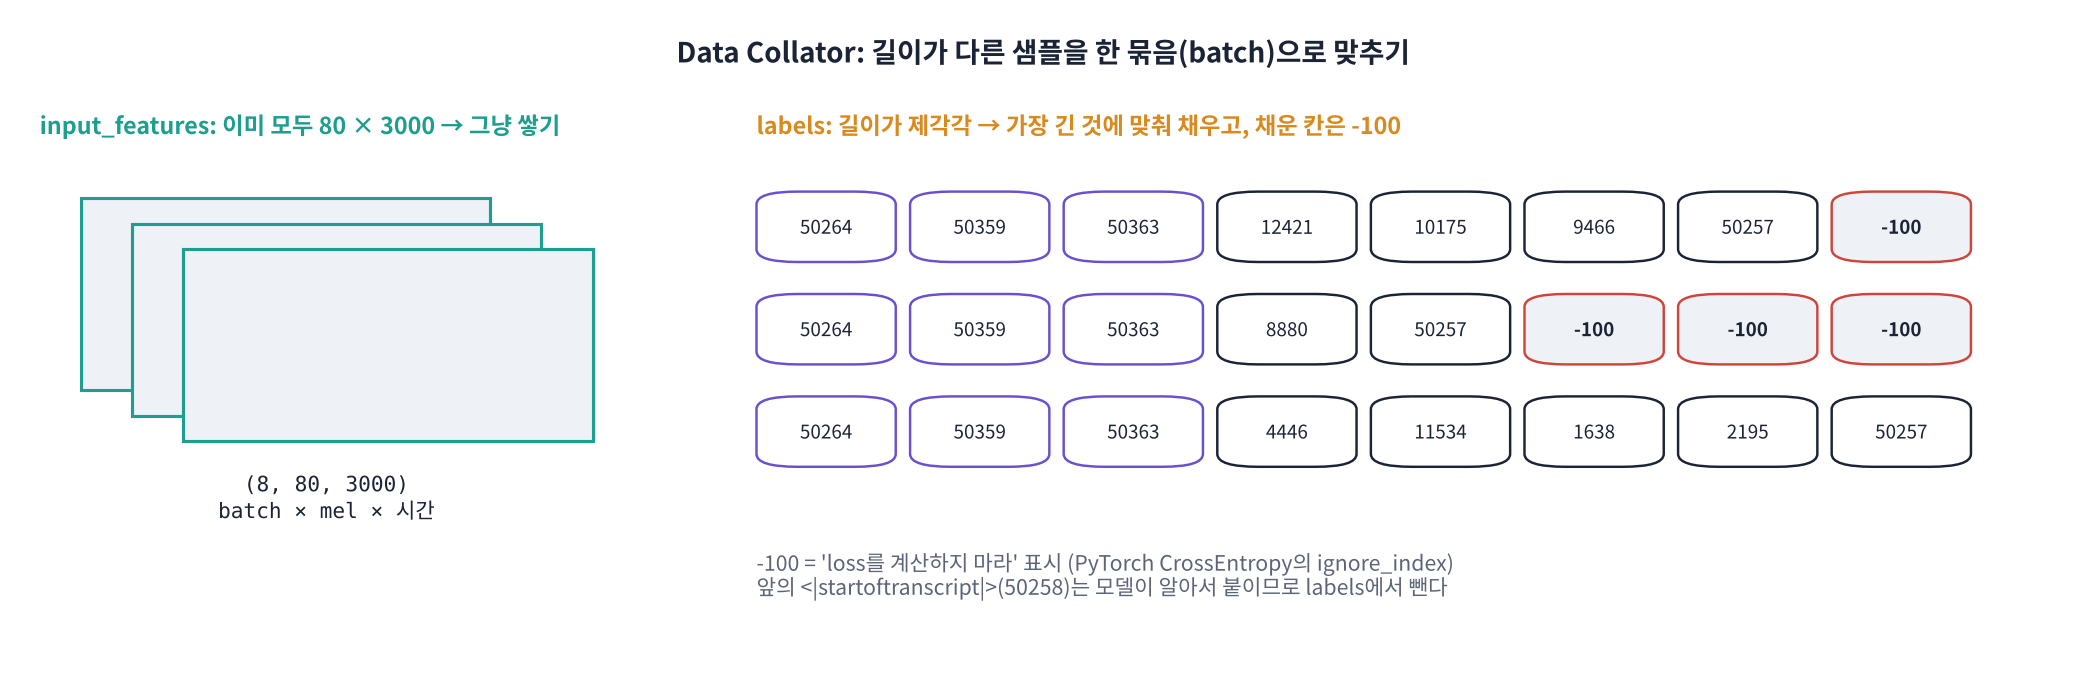

> 🍎 **비유: 시험지 채점.** 문항 수가 다른 시험지를 한 묶음으로 채점기에 넣으려고 빈칸을 덧붙였다면, 그 빈칸은 **채점하지 않도록 '채점 제외' 도장(−100)** 을 찍어 둡니다. 도장이 없으면 모델이 '빈칸을 맞히는 법'까지 배우느라 점수가 엉뚱해집니다.

| 처리 | 이유 |
|---|---|
| `feature_extractor.pad(..., return_tensors="pt")` | 80 × 3000 특징을 (batch, 80, 3000) 텐서로 |
| `tokenizer.pad(...)` | labels를 가장 긴 길이로 채우고 `attention_mask`(진짜 1 · 채움 0)도 만듦 |
| 채운 칸 → **−100** | PyTorch CrossEntropy의 `ignore_index=-100` → loss에서 빠짐 |
| 맨 앞 `<|startoftranscript|>` 빼기 | 모델이 decoder 입력을 만들 때 **스스로 앞에 붙이므로** 두 번 붙지 않게 |

> 🎬 **애니메이션 D12-4:** [Data Collator](https://imguru-mooc.github.io/AI_Voice/day12/animation.html#collator) — 샘플을 골라 묶음을 만들고 패딩 · −100 · 시작 토큰 처리 보기

### 🧩 빈칸 실습 1 · 2: Collator 만들기
- 빈칸 1: 채운 칸(`attention_mask`가 1이 아닌 곳)에 넣을 **loss 제외 값**
- 빈칸 2: 모든 labels의 첫 토큰이 **이 값**이면 잘라 냅니다 (클래스가 받아 둔 시작 토큰 ID)

In [ ]:
# 🧩 빈칸 실습 1 · 2
from dataclasses import dataclass

@dataclass
class DataCollatorSpeechSeq2SeqWithPadding:
    processor: object
    decoder_start_token_id: int

    def __call__(self, features):
        # ① 소리 쪽: 이미 같은 크기 → 텐서로 쌓기
        audio = [{"input_features": f["input_features"]} for f in features]
        batch = self.processor.feature_extractor.pad(audio, return_tensors="pt")
        # ② 글자 쪽: 가장 긴 길이로 채우기
        lab = [{"input_ids": f["labels"]} for f in features]
        lab_batch = self.processor.tokenizer.pad(lab, return_tensors="pt")
        labels = lab_batch["input_ids"].masked_fill(lab_batch.attention_mask.ne(1), ____)        # 빈칸 1
        # ③ 맨 앞 <|startoftranscript|> 는 모델이 다시 붙이므로 빼기
        if (labels[:, 0] == ____).all().cpu().item():                                            # 빈칸 2
            labels = labels[:, 1:]
        batch["labels"] = labels
        return batch

collator = DataCollatorSpeechSeq2SeqWithPadding(processor=processor, decoder_start_token_id=start)
b = collator([train_ds[i] for i in range(4)])
print({k: tuple(v.shape) for k, v in b.items()})
print("labels[0] 끝부분:", b["labels"][0][-6:].tolist())
print("−100 개수 (샘플별):", (b["labels"] == -100).sum(dim=1).tolist())
check(b["input_features"].shape[1:] == (80, 3000) and (b["labels"] == -100).any() and (b["labels"][:, 0] != start).all(),
      hint="빈칸 1 = -100, 빈칸 2 = self.decoder_start_token_id")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
labels = lab_batch["input_ids"].masked_fill(lab_batch.attention_mask.ne(1), -100)
if (labels[:, 0] == self.decoder_start_token_id).all().cpu().item():
```

**해설**: `masked_fill(조건, 값)`은 조건이 참인 칸을 값으로 바꿉니다. `attention_mask.ne(1)`은 '진짜 토큰이 아닌 칸' = 채운 칸입니다. Whisper의 pad 토큰은 `<|endoftext|>`와 같아서, −100으로 바꾸지 않으면 '끝 토큰을 여러 번 내라'고 잘못 배웁니다. 시작 토큰을 빼는 이유는 모델이 `labels`를 오른쪽으로 밀면서 `decoder_start_token_id`(= `<|startoftranscript|>`)를 앞에 붙이기 때문입니다(Part 1). 빼지 않으면 시작 토큰이 두 번 들어갑니다. **4개 샘플 중 가장 긴 것은 −100이 0개**입니다.

</details>

## Part 4. 모델 불러오기와 평가 지표 (학습 전 성능 재기)

> 💬 **쉽게 말하면**: 학습 중 점수는 **실제로 받아쓰게 한 뒤(generate) CER을 재는 함수** `compute_metrics`로 매깁니다. Trainer가 평가 때마다 이 함수에 `predictions`(예측 토큰)와 `label_ids`(정답 토큰, −100 포함)를 넘겨 줍니다.

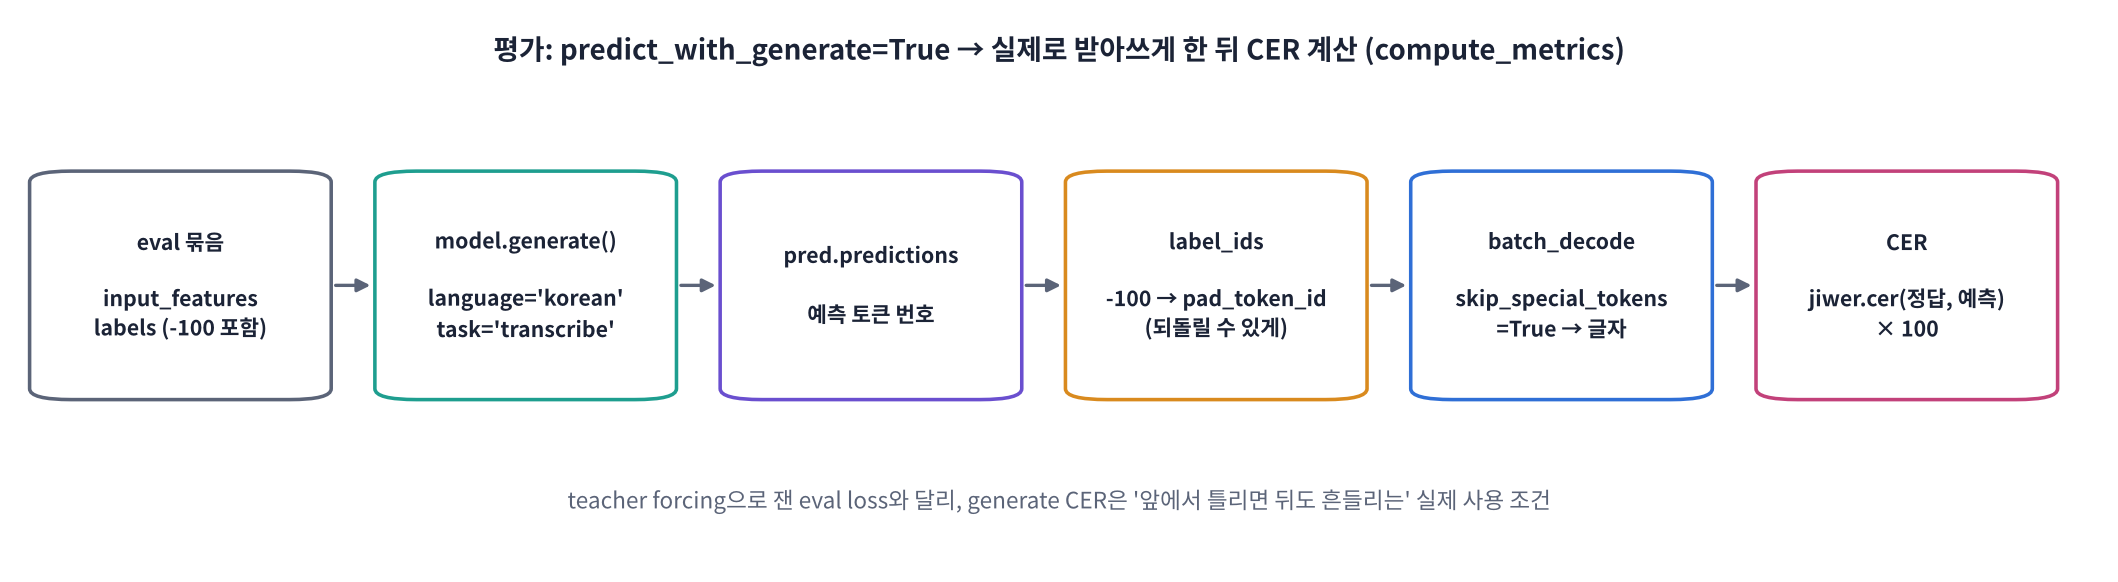

👣 **한 단계씩**
1. `label_ids`의 −100을 **pad 토큰**으로 되돌립니다(−100은 글자로 바꿀 수 없음).
2. 예측 · 정답을 `batch_decode(..., skip_special_tokens=True)`로 글자로 바꿉니다.
3. D10처럼 **문장 부호 · 띄어쓰기 차이를 정리(정규화)** 한 뒤 `jiwer.cer(정답, 예측)`.

> 🎬 **애니메이션 D12-8:** [평가 지표 계산](https://imguru-mooc.github.io/AI_Voice/day12/animation.html#metrics) — 예측 토큰이 CER이 되기까지

### 🧩 빈칸 실습 3 · 4: compute_metrics
- 빈칸 3: −100 자리에 되돌려 넣을 값 (tokenizer의 **pad 토큰 ID**)
- 빈칸 4: `jiwer.cer(정답, 예측)` — 정답 목록 변수 이름 (D10: 정답이 먼저)

In [ ]:
# 🧩 빈칸 실습 3 · 4
def normalize(s):                                       # D10 정규화의 간단판: 문장 부호 · 띄어쓰기 차이 무시
    s = re.sub(r"[^\w\s]", "", s.lower())
    return re.sub(r"\s+", "", s)

def compute_metrics(pred):
    pred_ids = pred.predictions
    label_ids = pred.label_ids.copy()
    label_ids[label_ids == -100] = ____                                              # 빈칸 3
    pred_str = [normalize(s) for s in processor.batch_decode(pred_ids, skip_special_tokens=True)]
    label_str = [normalize(s) for s in processor.batch_decode(label_ids, skip_special_tokens=True)]
    pred_str = [p if p else "∅" for p in pred_str]                                   # 빈 예측 대비
    return {"cer": 100 * jiwer.cer(____, pred_str)}                                  # 빈칸 4

# 확인: 정답을 그대로 '예측'으로 넣으면 CER 0, 한 글자 바꾸면 0보다 큼
from transformers import EvalPrediction
lab = collator([test_ds[i] for i in range(3)])["labels"].numpy()
ok = np.where(lab == -100, tok.pad_token_id, lab)
print("정답 = 예측:", compute_metrics(EvalPrediction(predictions=ok, label_ids=lab.copy())))
check(compute_metrics(EvalPrediction(predictions=ok, label_ids=lab.copy()))["cer"] == 0,
      hint="빈칸 3 = processor.tokenizer.pad_token_id, 빈칸 4 = label_str")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
label_ids[label_ids == -100] = processor.tokenizer.pad_token_id
return {"cer": 100 * jiwer.cer(label_str, pred_str)}
```

**해설**: −100은 어휘에 없는 번호라 `batch_decode`가 처리하지 못합니다. pad 토큰(`<|endoftext|>`)으로 되돌리면 `skip_special_tokens=True`가 깨끗이 지워 줍니다. `jiwer.cer(reference, hypothesis)`는 **정답이 먼저**입니다. 순서를 바꾸면 분모(정답 길이)가 바뀌어 다른 숫자가 나옵니다(D10). 오늘은 띄어쓰기까지 지워 **글자만 비교**합니다. Zeroth 전사에는 문장 부호가 없지만 Whisper는 마침표 · 쉼표를 붙이므로, 정규화하지 않으면 학습 전 CER이 실제보다 나빠 보입니다.

</details>

### 🧩 빈칸 실습 5: 모델 불러오기와 생성 설정
Whisper는 언어를 스스로 감지하기도 하지만(D7), 학습 · 평가에서는 **한국어 받아쓰기로 고정**합니다. `generation_config`에 언어를 넣으세요.

In [ ]:
# 🧩 빈칸 실습 5
from transformers import WhisperForConditionalGeneration

model = WhisperForConditionalGeneration.from_pretrained(CFG["model_name"])
model.generation_config.language = ____                                              # 빈칸 5
model.generation_config.task = "transcribe"
model.accepts_loss_kwargs = False          # ⚠️ 기울기 모으기(accum) 때 loss가 accum배로 커지는 문제 막기 (아래 설명)
n_params = sum(p.numel() for p in model.parameters())
print(f"{CFG['model_name']}: 파라미터 {n_params / 1e6:.0f}M · 학습 대상 {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.0f}M (Full Fine-tuning = 전부)")

# Teacher forcing loss 한 번 재 보기 (학습 전)
device = "cuda" if GPU else "cpu"
model.to(device)
with torch.no_grad():
    b = collator([train_ds[i] for i in range(4)])
    out = model(input_features=b["input_features"].to(device), labels=b["labels"].to(device))
print(f"학습 전 teacher forcing loss = {out.loss.item():.3f}  (정답 토큰 평균 확률 ≈ {np.exp(-out.loss.item()):.2f})")
check(model.generation_config.language in ("korean", "ko", "<|ko|>"), hint='빈칸 5 = "korean"')

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
model.generation_config.language = "korean"
```

**해설**: `language="korean"`(또는 `"ko"`)로 고정하면 평가 때 `<|ko|><|transcribe|>`가 앞에 붙어 언어 감지 실수가 사라지고, labels의 앞쪽 토큰(Part 1)과도 같아집니다. 학습 전 loss가 이미 낮다면(예: 0.5 안팎) Whisper가 한국어를 **이미 꽤 잘한다**는 뜻입니다. Fine-tuning은 여기서 조금 더 내리는 일입니다.

</details>

> ⚠️ **`model.accepts_loss_kwargs = False`는 왜 넣었나요? (transformers 5.x에서 직접 확인한 함정)**
> 오늘은 8개씩 **두 번 모아(gradient accumulation)** 한 번 고칩니다. Trainer는 원래 두 묶음의 loss를 **평균**내야 하는데, Whisper 모델이 'loss 계산을 스스로 맞춰 준다'고 잘못 판단하면 두 loss를 **그냥 더해 버립니다**. 그러면 ① 기록된 train loss가 eval loss의 **약 2배**로 보이고, ② 실제로도 **학습률을 2배로 쓴 것처럼** 크게 고쳐집니다. 이 한 줄로 Trainer가 직접 평균을 내게 합니다. (같은 설정에서 batch 16 × 1번과 8 × 2번의 가중치 변화량이 같아지는 것을 확인했습니다.)

### 4-1. 학습 전 받아쓰기 기록해 두기 (baseline)
학습 후 비교하려면 **같은 문장**의 학습 전 결과를 저장해 둬야 합니다. 5개만 직접 받아쓰게 해 봅니다. CER은 Part 5에서 Trainer로 100개 전체를 잽니다.

In [ ]:
def transcribe(model, rows, n=5):
    model.eval()
    feats = processor.feature_extractor([r["audio"] for r in rows[:n]], sampling_rate=SR, return_tensors="pt").input_features
    with torch.no_grad():
        ids = model.generate(feats.to(model.device, dtype=model.dtype), language="korean", task="transcribe", max_new_tokens=225)
    return processor.batch_decode(ids, skip_special_tokens=True)

t0 = time.time()
before = transcribe(model, test_rows)
for r, p in zip(test_rows, before):
    print(f"정답: {r['text']}\n학습 전: {p.strip()}\n")
print(f"{time.time() - t0:.1f}초")

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day12/worksheet.html)** — Data Collator, padding과 attention_mask, −100(ignore_index), 시작 토큰 빼기, compute_metrics, predictions · label_ids, batch_decode, jiwer.cer 순서, 정규화, generation_config
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 5. 학습 설정과 Seq2SeqTrainer

> 💬 **쉽게 말하면**: `Seq2SeqTrainingArguments`는 **학습 계획표**(얼마나 세게 · 얼마나 오래 · 언제 평가 · 어디 저장), `Seq2SeqTrainer`는 그 계획표대로 **반복 학습을 대신 돌려 주는 코치**입니다. 우리가 for 문으로 '묶음 꺼내기 → loss → 기울기 → 고치기'를 짤 필요가 없습니다.

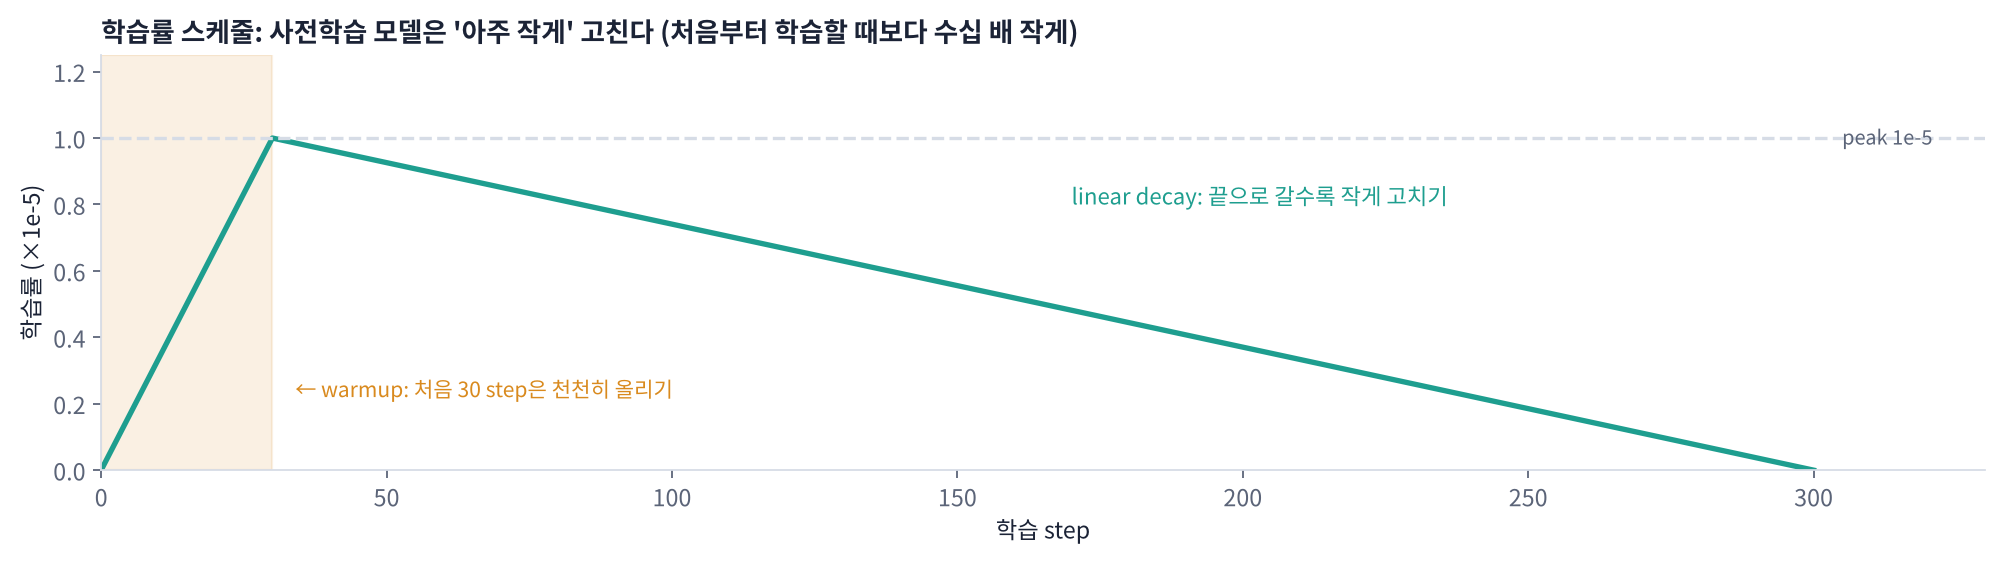

| 설정 | 오늘 값 | 뜻 |
|---|---|---|
| `learning_rate` | **1e-5** | 한 번에 얼마나 고칠지. 사전학습 모델은 **아주 작게** (처음부터 학습은 1e-3 안팎) |
| `warmup_steps` | 30 | 처음엔 천천히 올림 → 초반 큰 흔들림 방지 |
| `per_device_train_batch_size` × `gradient_accumulation_steps` | 8 × 2 = **16** | 기울기를 두 번 모아 한 번 고침 → 메모리는 8개 분량, 효과는 16개 |
| `max_steps` | 300 | 300번 고치기 = 16 × 300 = 4,800 샘플 (2,000개를 약 2.4바퀴) |
| `fp16` | GPU면 True | 절반 정밀도로 계산 → 빠르고 메모리 절약 |
| `eval_steps` · `save_steps` | 100 | 100 step마다 평가 · 저장 |
| `predict_with_generate` | **True** | 평가 때 실제로 받아쓰게 해서 CER 계산 |
| `load_best_model_at_end` · `metric_for_best_model` | True · `"cer"` | 끝나면 CER이 가장 낮았던 체크포인트로 되돌림 |
| `report_to` | `["tensorboard"]` | 학습 기록을 TensorBoard로 (W&B는 선택) |

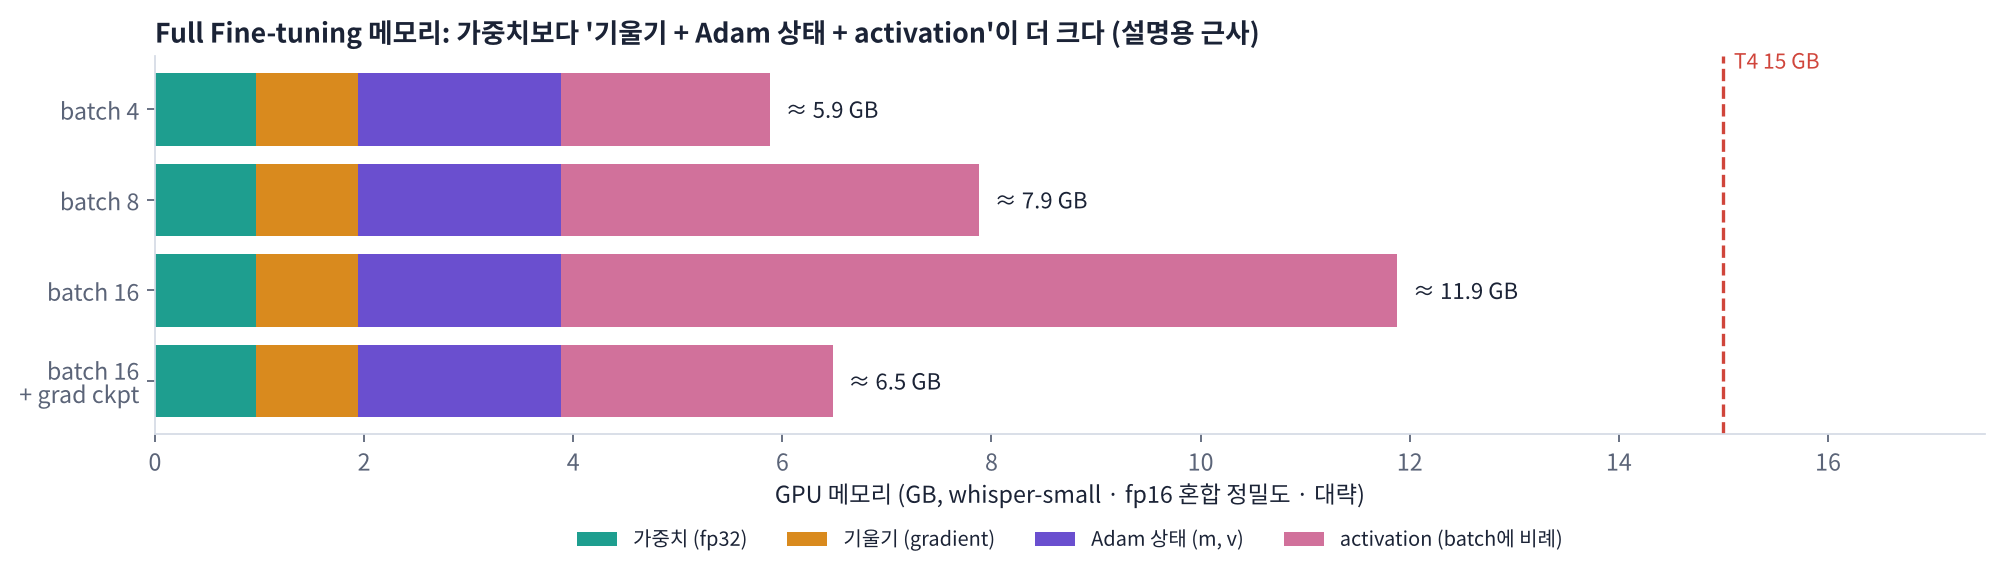

> 🍎 **비유: 기울기 모으기(gradient accumulation).** 큰 냄비(GPU 메모리)가 없어서 국을 두 번에 나눠 끓인 뒤 **한 솥에 합쳐 간을 보는 것**. 맛(학습 효과)은 큰 냄비로 한 번 끓인 것과 거의 같습니다.

> 🎬 **애니메이션 D12-5:** [학습률 실험실](https://imguru-mooc.github.io/AI_Voice/day12/animation.html#lr) — 학습률 · warmup을 바꾸며 loss가 어떻게 내려가는지
> 🎬 **애니메이션 D12-6:** [GPU 메모리 계산기](https://imguru-mooc.github.io/AI_Voice/day12/animation.html#memory) — 모델 크기 · batch · fp16 · Encoder 고정에 따른 메모리

### 🧩 빈칸 실습 6 · 7: 학습 설정
- 빈칸 6: 사전학습 모델 Fine-tuning에 쓰는 **아주 작은 학습률** (1 × 10⁻⁵)
- 빈칸 7: 평가 때 **실제로 받아쓰게(generate)** 해서 CER을 잴지 여부

(선택) **W&B**를 쓰려면 Colab 🔑 보안 비밀에 `WANDB_API_KEY`를 넣고 `USE_WANDB = True`로 바꾸세요.

In [ ]:
# 🧩 빈칸 실습 6 · 7
from transformers import Seq2SeqTrainingArguments

USE_WANDB = False
if USE_WANDB:
    !pip install -q -c colab_constraints.txt wandb
    from google.colab import userdata
    os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")
    os.environ["WANDB_PROJECT"] = "voice-ai-d12"
os.environ["TENSORBOARD_LOGGING_DIR"] = f"{CFG['out_dir']}/runs"        # TensorBoard 기록 위치

args = Seq2SeqTrainingArguments(
    output_dir=CFG["out_dir"],
    per_device_train_batch_size=CFG["batch"],
    gradient_accumulation_steps=CFG["accum"],
    learning_rate=____,                                  # 빈칸 6
    warmup_steps=max(1, CFG["max_steps"] // 10),
    max_steps=CFG["max_steps"],
    fp16=GPU,
    eval_strategy="steps",
    eval_steps=CFG["eval_steps"],
    save_steps=CFG["eval_steps"],
    logging_steps=max(1, CFG["eval_steps"] // 4),
    per_device_eval_batch_size=16,
    predict_with_generate=____,                          # 빈칸 7
    generation_max_length=225,
    load_best_model_at_end=True,
    metric_for_best_model="cer",
    greater_is_better=False,
    save_total_limit=2,
    remove_unused_columns=False,                         # set_transform을 쓰므로 열을 지우지 않음
    dataloader_num_workers=2,
    report_to=["tensorboard"] + (["wandb"] if USE_WANDB else []),
)
print(f"lr={args.learning_rate} · 실제 묶음 {args.per_device_train_batch_size * args.gradient_accumulation_steps} · "
      f"warmup {args.warmup_steps} · fp16={args.fp16} · generate={args.predict_with_generate}")
check(args.learning_rate == 1e-5 and args.predict_with_generate is True, hint="빈칸 6 = 1e-5, 빈칸 7 = True")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
learning_rate=1e-5,
predict_with_generate=True,
```

**해설**: `1e-5` = 0.00001. Whisper 논문 · Hugging Face 예제에서 small 크기 Fine-tuning에 흔히 쓰는 값입니다(모델이 클수록 더 작게: large는 5e-6 안팎). 너무 크면 원래 실력을 잊고(catastrophic forgetting) loss가 튀고, 너무 작으면 거의 변하지 않습니다. `predict_with_generate=False`면 평가 때 teacher forcing loss만 계산하고 CER은 못 잽니다. 생성은 느리므로 평가 세트를 작게(오늘 100개) 둡니다.

</details>

### 🧩 빈칸 실습 8: Trainer 만들고 학습 전 CER 재기
Trainer에 **모델 · 설정 · 데이터 · 묶음 만드는 함수 · 평가 함수**를 넘깁니다. 빈칸에는 Part 3에서 만든 **Collator 변수**를 넣으세요.

In [ ]:
# 🧩 빈칸 실습 8
from transformers import Seq2SeqTrainer

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    data_collator=____,                                  # 빈칸 8
    compute_metrics=compute_metrics,
    processing_class=processor,                          # (transformers 4.x의 tokenizer= 자리)
)

t0 = time.time()
base = trainer.evaluate()
print(f"학습 전: eval_loss {base['eval_loss']:.3f} · CER {base['eval_cer']:.2f}%  ({time.time() - t0:.0f}초)")
check(trainer.data_collator is collator and "eval_cer" in base, hint="빈칸 8 = collator")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
data_collator=collator,
```

**해설**: `data_collator`를 안 주면 기본 함수가 길이가 다른 labels를 묶지 못해 오류가 납니다. transformers 5.x에서는 `tokenizer=` 대신 **`processing_class=`** 를 씁니다(체크포인트에 processor도 함께 저장됨). `evaluate()`는 평가만 하고 가중치는 바꾸지 않습니다. 결과 키에 `eval_` 접두사가 붙어 `compute_metrics`의 `cer`가 `eval_cer`가 됩니다.

</details>

### 5-1. 🚀 학습 실행 (T4 약 20~30분)

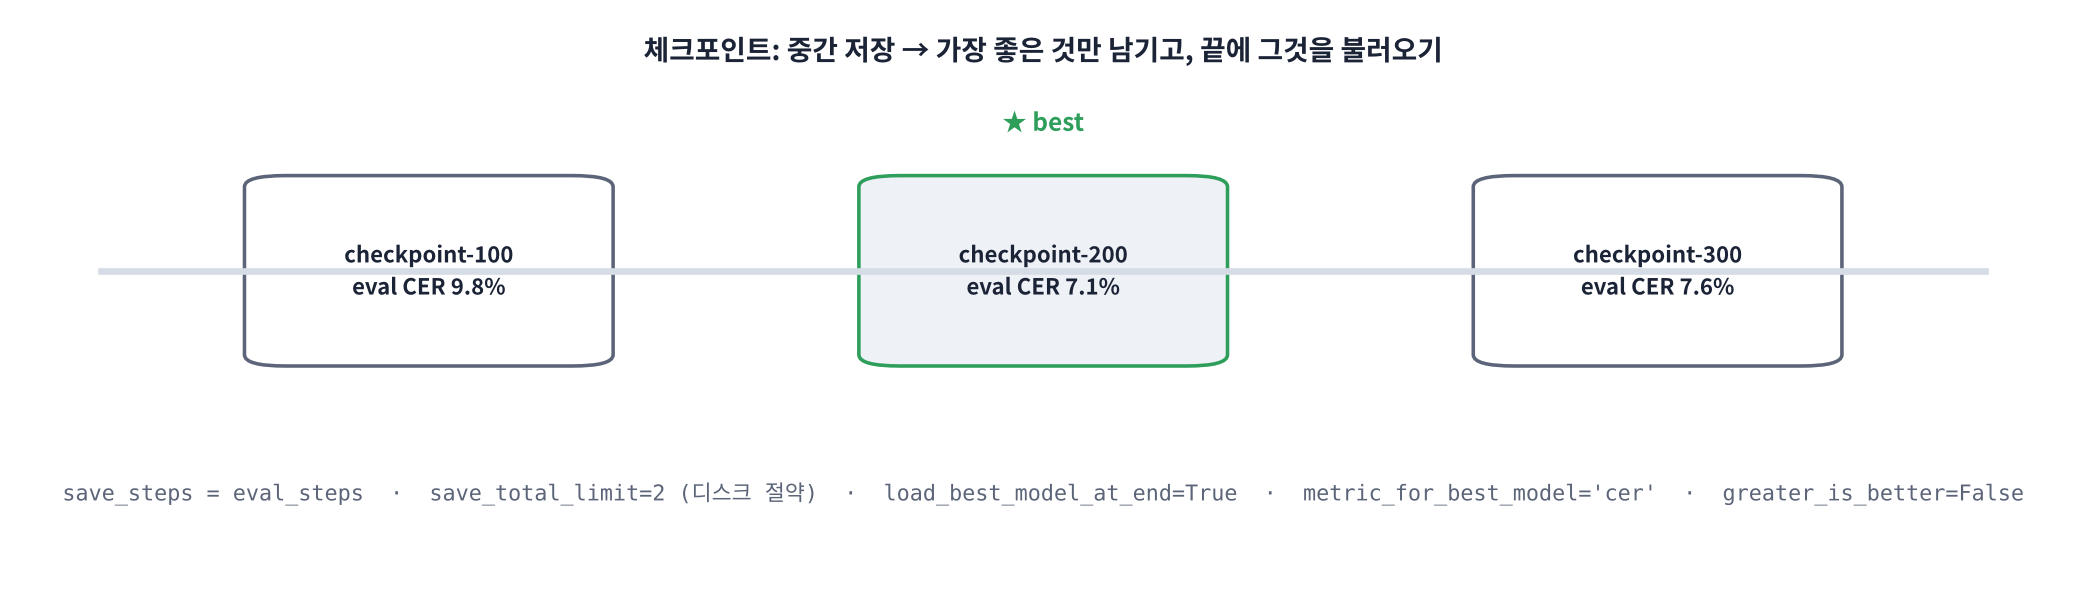

👣 **한 step 동안 일어나는 일**: 묶음 8개 꺼내기 → Collator → forward(teacher forcing) → loss → backward(기울기) → (2번 모아서) optimizer가 가중치를 조금 고침 → 학습률 조금 바꿈. 100 step마다 평가(생성 → CER)와 저장.

> ⚠️ **`CUDA out of memory`가 나면**: `CFG["batch"] = 4`, `CFG["accum"] = 4`로 바꾸고 Part 5부터 다시 실행 (실제 묶음은 그대로 16). 그래도 부족하면 `args.gradient_checkpointing=True` (느려지는 대신 메모리 절약).

> 🎬 **애니메이션 D12-7:** [학습 한 step 따라가기](https://imguru-mooc.github.io/AI_Voice/day12/animation.html#loop) — forward → loss → backward → update를 단계별로

In [ ]:
t0 = time.time()
result = trainer.train()
print(f"\n학습 끝: {(time.time() - t0) / 60:.1f}분 · step {result.global_step} · 평균 train loss {result.training_loss:.3f}")
print("가장 좋은 체크포인트:", trainer.state.best_model_checkpoint, "· best CER", trainer.state.best_metric)
if GPU:
    print(f"GPU 최대 메모리 사용: {torch.cuda.max_memory_allocated() / 1024**3:.1f} GB")

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day12/worksheet.html)** — learning rate · warmup · decay, batch와 gradient accumulation, step과 epoch, fp16, GPU 메모리 구성(가중치 · 기울기 · Adam · activation), eval · save steps, load_best_model_at_end, processing_class, remove_unused_columns
>
> 학습이 도는 동안 풀어도 좋습니다.

## Part 6. 학습 모니터링: 곡선 읽기

> 💬 **쉽게 말하면**: 학습은 **곡선으로 읽습니다**. train loss는 내려가는데 eval loss · CER이 다시 올라가면 **과적합**(학습 데이터를 외우기 시작), loss가 튀거나 오르면 **학습률이 너무 큼**, 거의 안 변하면 **너무 작음**입니다.

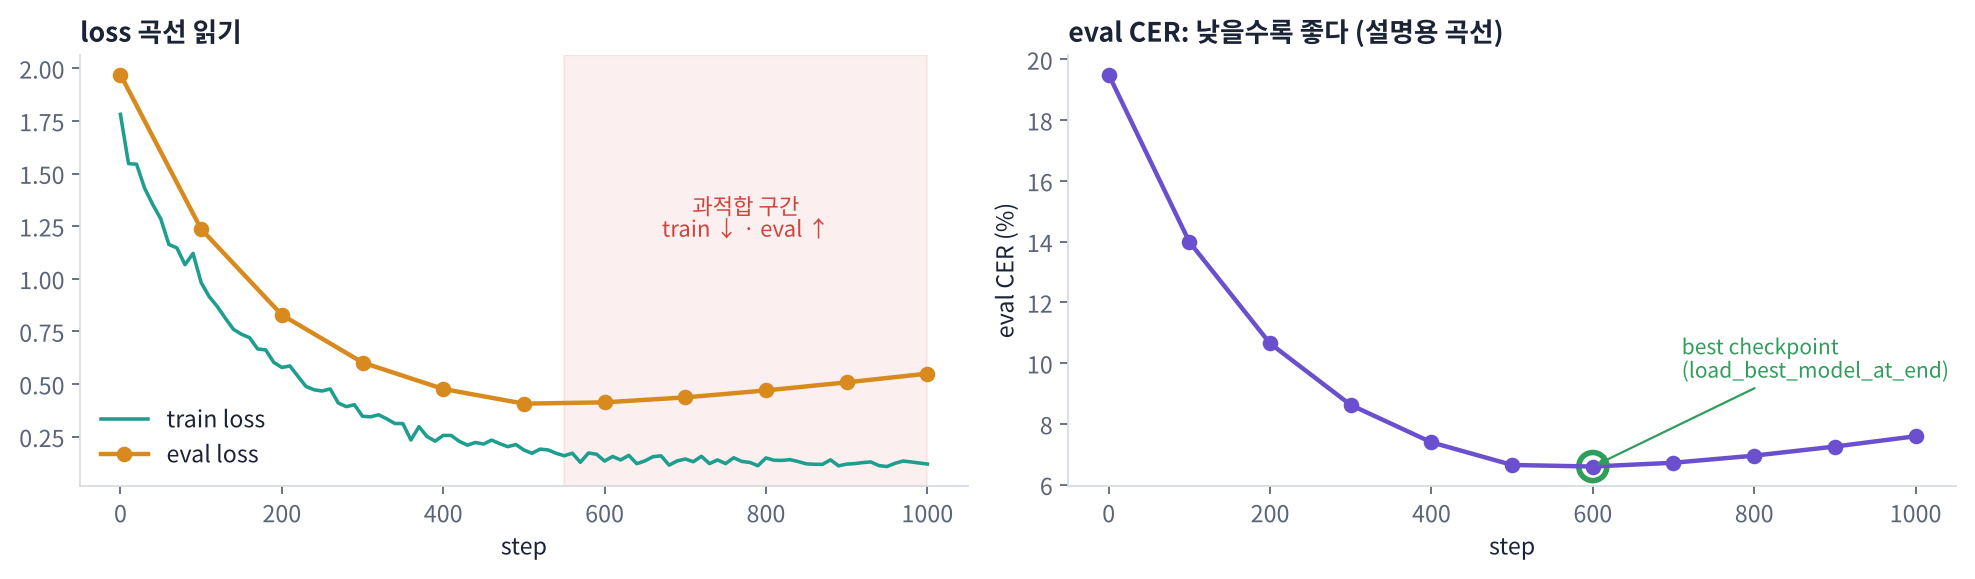

| 곡선 모양 | 뜻 | 조치 |
|---|---|---|
| train ↓ · eval ↓ | 잘 배우는 중 | 더 학습해 볼 만함 |
| train ↓ · eval ↑ | **과적합** | best 체크포인트 사용, 데이터 늘리기, step 줄이기 |
| loss 튐 · NaN | 학습률 너무 큼 · fp16 넘침 | lr 낮추기, warmup 늘리기 |
| 거의 평평 | 학습률 너무 작음 · 이미 잘함 | lr 올리기, 데이터 점검 |

> 🎬 **애니메이션 D12-9:** [곡선 읽기 연습](https://imguru-mooc.github.io/AI_Voice/day12/animation.html#curves) — 곡선 모양을 보고 무슨 일이 일어났는지 맞히기

### 6-1. TensorBoard
Colab 안에 TensorBoard 화면이 열립니다. 왼쪽에서 `train/loss`, `eval/cer`, `train/learning_rate`를 보세요. (W&B를 켰다면 출력의 링크에서 같은 그래프를 볼 수 있습니다.)

In [ ]:
%load_ext tensorboard
%tensorboard --logdir {CFG["out_dir"]}/runs

### 🧩 빈칸 실습 9: 기록에서 곡선 직접 그리기
`trainer.state.log_history`는 기록 사전들의 목록입니다. 학습 기록에는 `loss`, 평가 기록에는 `eval_loss` · `eval_cer`가 들어 있습니다. 평가 CER만 고르는 **키 이름**을 넣으세요.

In [ ]:
# 🧩 빈칸 실습 9
log = trainer.state.log_history
tr = [(h["step"], h["loss"]) for h in log if "loss" in h]
ev = [(h["step"], h["eval_loss"], h["eval_cer"]) for h in log if ____ in h]             # 빈칸 9
ev = [(0, base["eval_loss"], base["eval_cer"])] + ev                                      # 학습 전(step 0) 추가

fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
axs[0].plot(*zip(*tr), label="train loss"); axs[0].plot([e[0] for e in ev], [e[1] for e in ev], "o-", label="eval loss")
axs[0].set_xlabel("step"); axs[0].legend(); axs[0].set_title("loss")
axs[1].plot([e[0] for e in ev], [e[2] for e in ev], "o-", color="tab:purple"); axs[1].set_xlabel("step"); axs[1].set_title("eval CER (%)")
plt.tight_layout(); plt.show()
print(pd.DataFrame(ev, columns=["step", "eval_loss", "eval_cer"]).round(3).to_string(index=False))
check(len(ev) >= 2 and all(len(e) == 3 for e in ev), hint='빈칸 9 = "eval_cer"')

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
ev = [(h["step"], h["eval_loss"], h["eval_cer"]) for h in log if "eval_cer" in h]
```

**해설**: 평가 기록만 `eval_cer` 키를 가집니다. 마지막 기록(`train_runtime` 등 요약)에는 `loss` 대신 `train_loss`가 있어 첫 줄 필터에도 걸리지 않습니다. **표의 step 0(학습 전) → 마지막 CER**이 오늘 Fine-tuning의 효과입니다. 2,000개 · 300 step의 짧은 학습이라도 Zeroth 말투(뉴스 낭독 · 띄어쓰기 습관)에 맞춰지면서 CER이 내려가는 것이 보통입니다. 숫자는 GPU · 무작위성에 따라 조금씩 다릅니다.

</details>

## Part 7. 전 · 후 비교, 저장, 다시 불러 쓰기

> 💬 **쉽게 말하면**: 숫자(CER)만 보지 말고 **같은 문장을 나란히** 놓고 무엇이 좋아졌는지 · 나빠졌는지 직접 읽어 봅니다. 그다음 모델과 processor를 **한 폴더에 저장**하면 `pipeline` 한 줄로 다시 쓸 수 있습니다(D14에서 Hugging Face Hub에 올림).

In [ ]:
after = transcribe(trainer.model, test_rows)
rows = []
for r, b0, a0 in zip(test_rows, before, after):
    rows.append(dict(정답=r["text"], 학습전=b0.strip(), 학습후=a0.strip(),
                     CER전=round(100 * jiwer.cer(normalize(r["text"]), normalize(b0) or "∅"), 1),
                     CER후=round(100 * jiwer.cer(normalize(r["text"]), normalize(a0) or "∅"), 1)))
cmp = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 60)
display(cmp)
final = trainer.evaluate()
print(f"\n시험 세트 {len(test_rows)}개 CER: 학습 전 {base['eval_cer']:.2f}% → 학습 후 {final['eval_cer']:.2f}%")

**결과 읽기**: 좋아진 문장은 주로 **띄어쓰기 · 숫자 표기 · 문장 부호 습관**이 Zeroth 전사 방식에 맞춰진 경우가 많습니다. 소리를 더 잘 듣게 됐다기보다 **'이 데이터셋의 받아쓰기 규칙'을 배운 부분**도 크다는 뜻입니다. 그래서 D14에서는 **다른 데이터**(내 녹음, 다른 도메인)에서도 좋아졌는지 확인합니다.

**❓ 생각해 보기**: Zeroth(뉴스 낭독)로 Fine-tuning한 모델이 회의 녹음이나 영어 문장도 더 잘 받아쓸까요?

<details>
<summary>답 보기</summary>

**보장되지 않습니다.** 낭독 말투 · 뉴스 어휘에 맞춰지면서 다른 말투나 영어 실력이 오히려 떨어질 수 있습니다(catastrophic forgetting). 그래서 ① 학습률을 작게, step을 적당히, ② **서비스와 비슷한 데이터**로 학습하고, ③ 원래 잘하던 것(일반 문장 · 영어)도 따로 평가합니다. 여러 도메인을 오가야 하면 D13의 **LoRA**처럼 원래 모델은 두고 작은 덧붙임만 바꿔 끼우는 방법이 유리합니다.

</details>

### 7-1. 저장하고 pipeline으로 다시 불러 쓰기

In [ ]:
FINAL = f"{CFG['out_dir']}/final"
trainer.save_model(FINAL)                  # 가중치 + config + generation_config
processor.save_pretrained(FINAL)           # 특징 추출기 + 토크나이저
!ls -la {FINAL}
!du -sh {FINAL}

from transformers import pipeline
asr = pipeline("automatic-speech-recognition", model=FINAL, device=0 if GPU else -1)
r = test_rows[1]
print("정답:", r["text"])
print("예측:", asr({"raw": r["audio"], "sampling_rate": SR}, generate_kwargs={"language": "korean", "task": "transcribe"})["text"])
print("✅ 저장한 모델을 다시 불러 받아쓰기 완료 — D14에서 Hugging Face Hub 업로드 · 상용 API와 비교")

> 💾 **Colab 세션이 끝나면 폴더가 사라집니다.** 내일(D13 · D14) 다시 쓰려면 Google Drive에 복사해 두세요. 아래 셀의 주석(`#`)을 지우고 실행합니다(약 1 GB).

In [ ]:
# from google.colab import drive
# drive.mount("/content/drive")
# !cp -r {FINAL} /content/drive/MyDrive/whisper-small-ko-d12

---
### 📝 4교시 마무리: 개념 워크시트 · 제출

> **[worksheet.html 열기 → 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day12/worksheet.html)** — 곡선 읽기(과적합 · 학습률), TensorBoard · W&B, log_history, best checkpoint, 전 · 후 비교, catastrophic forgetting, save_model · save_pretrained, pipeline
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 8. 정리 & 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| Fine-tuning | 사전학습 모델을 우리 데이터로 조금 더 학습 | `WhisperForConditionalGeneration.from_pretrained(...)` |
| Teacher forcing | 정답 앞부분을 보고 다음 토큰 맞히기, loss = −log P(정답) | `model(input_features=..., labels=...)` |
| set_transform | 꺼낼 때마다 특징 · 토큰 만들기 | `ds.set_transform(prepare_batch)` |
| Data Collator | 묶음 만들기, 패딩 → −100, 시작 토큰 빼기 | `masked_fill(mask.ne(1), -100)` |
| compute_metrics | 생성 → 글자 → 정규화 → CER | `jiwer.cer(label_str, pred_str)` |
| 학습 설정 | lr 1e-5 · warmup · 8×2 · fp16 · 생성 평가 | `Seq2SeqTrainingArguments(...)` |
| Trainer | 반복 학습 · 평가 · 저장을 대신 | `Seq2SeqTrainer(..., data_collator=collator)` |
| 모니터링 | 곡선으로 과적합 · 학습률 문제 읽기 | `%tensorboard`, `trainer.state.log_history` |
| 저장 · 추론 | 모델 + processor 한 폴더 → pipeline | `save_model`, `save_pretrained`, `pipeline(...)` |

### 📝 과제
1. **학습률 실험**: `learning_rate`를 `1e-4`와 `1e-6`으로 바꿔(다른 값은 그대로, `max_steps=100`) 학습한 뒤 오늘 결과(1e-5)와 eval CER 곡선을 한 그림에 겹쳐 그리고, 무엇이 달랐는지 세 줄로 쓰세요.
2. **Encoder 고정**: `model.freeze_encoder()`를 학습 전에 호출해 Decoder만 학습하고, GPU 최대 메모리 · 학습 시간 · 최종 CER을 Full Fine-tuning과 표로 비교하세요.
3. **(선택) 내 목소리 시험**: 뉴스 문장 3개와 평소 말투 문장 3개를 직접 녹음해 학습 전 · 후 모델로 받아쓰고 차이를 정리하세요.

### ✅ 개념 워크시트 제출
4교시 탭까지 모두 채점했다면 오늘 내용을 정리해 제출합니다.

> 📝 **[D12 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day12/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)

**제출 방법 (노션)**
1. 4개 교시 탭을 모두 채점합니다.
2. **제출** 버튼을 눌러 오답 정리를 엽니다.
3. **📋 캡처 (노션용 복사)**를 누른 뒤, 노션 제출 페이지에서 `Ctrl + V`로 붙여 넣습니다.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day12/animation.html) — D12-1 ~ D12-9

### 다음 시간 (D13)
**PEFT / LoRA Fine-tuning**: 오늘처럼 2.4억 개를 다 고치지 않고 **1% 미만의 작은 덧붙임 행렬만** 학습합니다. 8-bit 로딩과 함께 **저사양 GPU**에서도 더 큰 모델(medium · large)을 다루고, 의료 · 법률 · 산업 같은 **도메인 용어**에 특화시켜 봅니다. 오늘의 Collator · compute_metrics · Trainer 코드를 거의 그대로 다시 씁니다.